In [ ]:
%pip install -q yfinance xgboost scikit-learn matplotlib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
TICKER = "Reliance.NS"
PERIOD = "10y"
print("Configuration Loaded")
print("Stock: ", TICKER)
print("Historical Period: ", PERIOD)

Configuration Loaded
Stock:  Reliance.NS
Historical Period:  10y


In [ ]:
raw = yf.Ticker(TICKER).history(
    period=PERIOD,
    interval="1d",
    auto_adjust=True,
    actions=False
)

if raw.empty:
    raise ValueError(
        f"No data received for {TICKER}. "
        "Check the ticker symbol or try again later."
    )

required_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

missing_columns = set(required_columns) - set(raw.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

prices = raw[required_columns].copy()
prices = prices.sort_index()
prices = prices[~prices.index.duplicated(keep="last")]
prices = prices.dropna(subset=required_columns)

if prices.index.tz is not None:
    prices.index = prices.index.tz_localize(None)

print("Data downloaded successfully.")
print(f"Stock: {TICKER}")
print(f"Rows: {len(prices):,}")
print(f"First date: {prices.index.min().date()}")
print(f"Last date: {prices.index.max().date()}")

display(prices.head())
display(prices.tail())

print("\nMissing values:")
display(prices.isna().sum())

Data downloaded successfully.
Stock: Reliance.NS
Rows: 2,473
First date: 2016-10-17
Last date: 2026-10-16


,Open,High,Low,Close,Volume
Date,,,,,
2016-10-17,235.564304,235.738806,230.929359,231.343781,9826781
2016-10-18,232.510729,236.164170,231.649184,235.804276,11073137
2016-10-19,236.534935,238.770624,235.869688,237.167465,17073242
2016-10-20,238.607031,239.490402,236.447695,237.211105,10125508
2016-10-21,239.272294,239.272294,230.853043,232.118118,43608816


,Open,High,Low,Close,Volume
Date,,,,,
2026-10-12,1180.300049,1185.500000,1153.199951,1158.900024,11338332
2026-10-13,1158.900024,1168.300049,1152.199951,1166.699951,10988483
2026-10-14,1167.000000,1188.000000,1162.699951,1174.599976,10938195
2026-10-15,1185.199951,1218.800049,1177.199951,1215.000000,23456219
2026-10-16,1215.000000,1215.400024,1193.000000,1211.199951,17225283



Missing values:


,0
Open,0
High,0
Low,0
Close,0
Volume,0


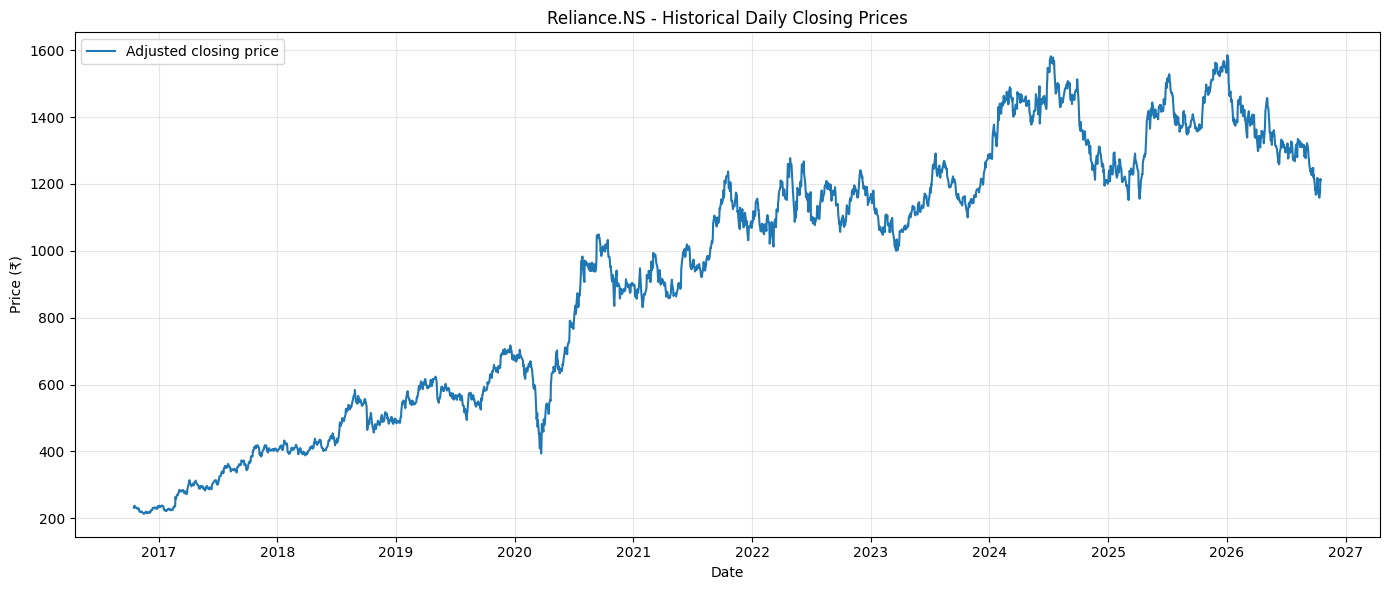

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    prices.index,
    prices["Close"],
    label="Adjusted closing price"
)

plt.title(f"{TICKER} - Historical Daily Closing Prices")
plt.xlabel("Date")
plt.ylabel("Price (₹)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
close = prices["Close"]
volume = prices["Volume"]
daily_returns = close.pct_change()

features = pd.DataFrame(index=prices.index)

features["return_1d"] = close.pct_change(1)
features["return_2d"] = close.pct_change(2)
features["return_5d"] = close.pct_change(5)
features["return_10d"] = close.pct_change(10)

for window in [5, 10, 20, 50]:
    moving_average = close.rolling(window).mean()
    features[f"price_vs_ma_{window}"] = (
        close / moving_average - 1
    )

features["volatility_5d"] = daily_returns.rolling(5).std()
features["volatility_10d"] = daily_returns.rolling(10).std()
features["volatility_20d"] = daily_returns.rolling(20).std()

features["volume_change_1d"] = volume.pct_change(1)
features["volume_vs_ma_20"] = (
    volume / volume.rolling(20).mean() - 1
)

features["intraday_return"] = (
    prices["Close"] / prices["Open"] - 1
)

features["daily_range"] = (
    prices["High"] - prices["Low"]
) / prices["Close"]

target_return = close.shift(-1) / close - 1

dataset = features.join(
    target_return.rename("target_return")
)

dataset = dataset.replace(
    [np.inf, -np.inf], np.nan
).dropna()

print("Feature engineering completed.")
print("Number of observations:", len(dataset))
print("Number of features:", len(features.columns))
print("Feature columns:", features.columns.tolist())

display(dataset.head())

Feature engineering completed.
Number of observations: 2421
Number of features: 15
Feature columns: ['return_1d', 'return_2d', 'return_5d', 'return_10d', 'price_vs_ma_5', 'price_vs_ma_10', 'price_vs_ma_20', 'price_vs_ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'volume_change_1d', 'volume_vs_ma_20', 'intraday_return', 'daily_range']


,return_1d,return_2d,return_5d,return_10d,price_vs_ma_5,price_vs_ma_10,price_vs_ma_20,price_vs_ma_50,volatility_5d,volatility_10d,volatility_20d,volume_change_1d,volume_vs_ma_20,intraday_return,daily_range,target_return
Date,,,,,,,,,,,,,,,,
2016-12-27,0.016469,0.006999,0.006428,0.023947,0.007085,0.006704,0.030047,0.036391,0.010903,0.009913,0.009426,0.138436,0.236508,0.016081,0.018879,-0.014089
2016-12-28,-0.014089,0.002148,-0.012744,-0.009250,-0.004552,-0.006559,0.012613,0.022008,0.012510,0.009275,0.009916,-0.447492,-0.270376,-0.017043,0.021387,0.015004
2016-12-29,0.015004,0.000704,0.011487,0.011871,0.008071,0.007156,0.024461,0.037658,0.013854,0.010296,0.010227,-0.089754,-0.326026,0.014714,0.018114,0.015909
2016-12-30,0.015909,0.031152,0.023740,0.023885,0.019267,0.020742,0.036392,0.054268,0.015164,0.011293,0.010480,0.791084,0.192347,0.016529,0.020233,0.002495
2017-01-02,0.002495,0.018443,0.035945,0.021223,0.014615,0.021117,0.034458,0.056948,0.013210,0.011254,0.010419,-0.548250,-0.467641,0.001015,0.016266,0.003963


In [ ]:
split_idx = int(len(dataset) * 0.80)

train = dataset.iloc[:split_idx - 1].copy()
test = dataset.iloc[split_idx:].copy()

feature_cols = [
    col for col in dataset.columns
    if col != "target_return"
]

X_train = train[feature_cols]
y_train = train["target_return"]

X_test = test[feature_cols]
y_test = test["target_return"]

print(f"Training observations: {len(train)}")
print(f"Testing observations: {len(test)}")
print(
    "Training period:",
    train.index.min().date(),
    "to",
    train.index.max().date()
)
print(
    "Testing period:",
    test.index.min().date(),
    "to",
    test.index.max().date()
)

Training observations: 1935
Testing observations: 485
Training period: 2016-12-27 to 2024-10-25
Testing period: 2024-10-29 to 2026-10-15


In [ ]:
from xgboost import XGBRegressor

model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("XGBoost training completed.")

XGBoost training completed.


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

predicted_returns = model.predict(X_test)

current_close = close.reindex(test.index)
actual_next_close = close.shift(-1).reindex(test.index)

predicted_prices = (
    current_close.to_numpy()
    * (1 + predicted_returns)
)

actual_prices = actual_next_close.to_numpy()

baseline_prices = current_close.to_numpy()

mae = mean_absolute_error(
    actual_prices, predicted_prices
)

rmse = np.sqrt(
    mean_squared_error(actual_prices, predicted_prices)
)

baseline_mae = mean_absolute_error(
    actual_prices, baseline_prices
)

baseline_rmse = np.sqrt(
    mean_squared_error(actual_prices, baseline_prices)
)

actual_returns = y_test.to_numpy()

direction_accuracy = 100 * np.mean(
    (predicted_returns > 0) == (actual_returns > 0)
)

print("TEST RESULTS")
print("-" * 40)
print(f"XGBoost MAE:          ₹{mae:.2f}")
print(f"XGBoost RMSE:         ₹{rmse:.2f}")
print(f"Baseline MAE:         ₹{baseline_mae:.2f}")
print(f"Baseline RMSE:        ₹{baseline_rmse:.2f}")
print(f"Direction accuracy:   {direction_accuracy:.2f}%")

print("\nPrice error comparison:")
print(f"MAE improvement: {(1 - mae / baseline_mae) * 100:.2f}%")

TEST RESULTS
----------------------------------------
XGBoost MAE:          ₹13.77
XGBoost RMSE:         ₹17.99
Baseline MAE:         ₹13.30
Baseline RMSE:        ₹17.56
Direction accuracy:   48.25%

Price error comparison:
MAE improvement: -3.56%


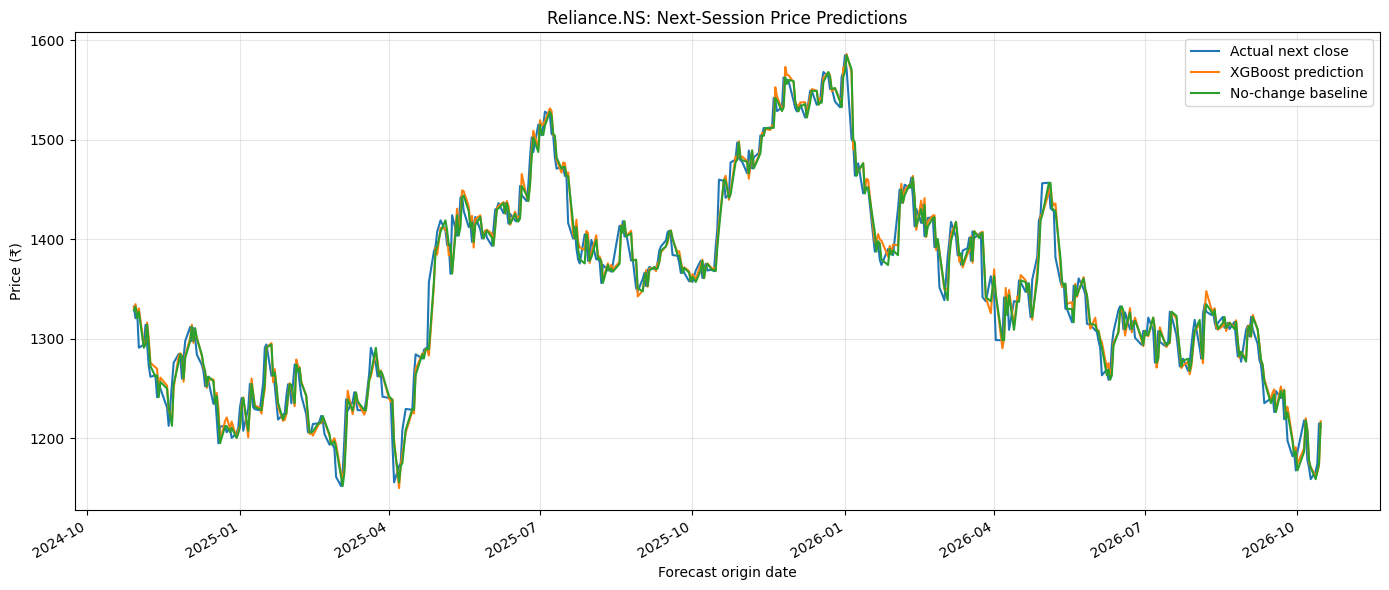

In [ ]:
results = pd.DataFrame({
    "Actual next close": actual_prices,
    "XGBoost prediction": predicted_prices,
    "No-change baseline": baseline_prices
}, index=test.index)

results.plot(figsize=(14, 6))

plt.title(f"{TICKER}: Next-Session Price Predictions")
plt.xlabel("Forecast origin date")
plt.ylabel("Price (₹)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Importance
price_vs_ma_10,0.124674
return_10d,0.079848
price_vs_ma_20,0.076360
volatility_20d,0.074853
return_1d,0.070186
intraday_return,0.067378
price_vs_ma_50,0.060404
return_2d,0.059143
volatility_10d,0.058498
return_5d,0.058448


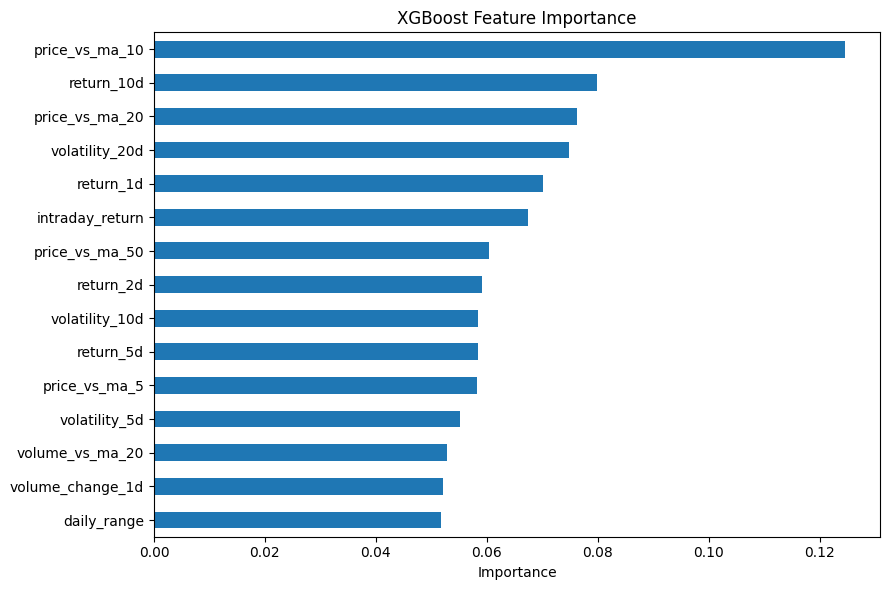

In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

display(importance.to_frame("Importance").head(15))

importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
NEWS_URL = (
    "https://huggingface.co/datasets/"
    "mveen3/Six_Year_Indian_Stock_Market_Dataset-News_and_Ticker/"
    "resolve/main/dataset/news_sentiment.csv"
)

news_sentiment = pd.read_csv(NEWS_URL)

print("Dataset shape:", news_sentiment.shape)
print("\nColumns:")
print(news_sentiment.columns.tolist())

print("\nFirst five rows:")
display(news_sentiment.head())

print("\nDate range, if a date column exists:")
date_col = next(
    (
        col for col in ["Date", "date"]
        if col in news_sentiment.columns
    ),
    None
)

if date_col:
    dates = pd.to_datetime(
        news_sentiment[date_col], errors="coerce"
    )
    print("Start:", dates.min())
    print("End:", dates.max())
else:
    print("No recognized date column; inspect the columns above.")

print("\nMissing values:")
display(news_sentiment.isna().sum())

Dataset shape: (114100, 14)

Columns:
['Date', 'Symbol', 'direct_news_pos', 'direct_news_neu', 'direct_news_neg', 'sectoral_news_pos', 'sectoral_news_neu', 'sectoral_news_neg', 'global_news_pos', 'global_news_neu', 'global_news_neg', 'direct_news_count', 'sectoral_news_count', 'global_news_count']

First five rows:


,Date,Symbol,direct_news_pos,direct_news_neu,direct_news_neg,sectoral_news_pos,sectoral_news_neu,sectoral_news_neg,global_news_pos,global_news_neu,global_news_neg,direct_news_count,sectoral_news_count,global_news_count
0,2020-01-01,ADANIENT,0.0,0.0,0.0,0.535922,0.197988,0.266090,0.494288,0.296691,0.209021,0,18,30
1,2020-01-01,ADANIPORTS,0.0,0.0,0.0,0.535922,0.197988,0.266090,0.494288,0.296691,0.209021,0,18,30
2,2020-01-01,APOLLOHOSP,0.0,0.0,0.0,0.137459,0.495285,0.367256,0.494288,0.296691,0.209021,0,2,30
3,2020-01-01,ASIANPAINT,0.0,0.0,0.0,0.958036,0.023065,0.018899,0.494288,0.296691,0.209021,0,1,30
4,2020-01-01,AXISBANK,0.0,0.0,0.0,0.364883,0.133411,0.501706,0.494288,0.296691,0.209021,0,33,30



Date range, if a date column exists:
Start: 2020-01-01 00:00:00
End: 2026-03-31 00:00:00

Missing values:


,0
Date,0
Symbol,0
direct_news_pos,0
direct_news_neu,0
direct_news_neg,0
sectoral_news_pos,0
sectoral_news_neu,0
sectoral_news_neg,0
global_news_pos,0
global_news_neu,0


In [ ]:
news_sentiment["Date"] = pd.to_datetime(
    news_sentiment["Date"], errors="coerce"
).dt.normalize()

news_sentiment["Symbol"] = (
    news_sentiment["Symbol"].astype(str).str.upper().str.strip()
)

reliance_news = news_sentiment.loc[
    news_sentiment["Symbol"] == "RELIANCE"
].copy()

if reliance_news.empty:
    raise ValueError(
        "RELIANCE was not found in the news dataset. "
        "Check the available symbols."
    )

sources = ["direct", "sectoral", "global"]

probability_cols = [
    f"{source}_news_{sentiment}"
    for source in sources
    for sentiment in ["pos", "neu", "neg"]
]

count_cols = [
    f"{source}_news_count"
    for source in sources
]

required_cols = ["Date"] + probability_cols + count_cols

missing_cols = set(required_cols) - set(reliance_news.columns)

if missing_cols:
    raise ValueError(f"Missing columns: {sorted(missing_cols)}")

aggregation = {col: "mean" for col in probability_cols}
aggregation.update({col: "sum" for col in count_cols})

reliance_news = (
    reliance_news[required_cols]
    .groupby("Date", as_index=False)
    .agg(aggregation)
    .sort_values("Date")
)

calendar = pd.date_range(
    start=reliance_news["Date"].min(),
    end=reliance_news["Date"].max(),
    freq="D",
    name="Date"
)

news_daily = (
    reliance_news.set_index("Date")
    .reindex(calendar)
)

news_daily = news_daily.apply(
    pd.to_numeric, errors="coerce"
).fillna(0)

sentiment_features = pd.DataFrame(index=calendar)

for source in sources:
    count = news_daily[f"{source}_news_count"].clip(lower=0)

    net_sentiment = (
        news_daily[f"{source}_news_pos"]
        - news_daily[f"{source}_news_neg"]
    )

    previous_count = count.rolling(
        window=3, min_periods=1
    ).sum().shift(1)

    previous_weighted_sentiment = (
        (net_sentiment * count)
        .rolling(window=3, min_periods=1)
        .sum()
        .shift(1)
    )

    sentiment_features[
        f"{source}_sentiment_prev3d"
    ] = (
        previous_weighted_sentiment
        / previous_count.replace(0, np.nan)
    ).fillna(0)

    sentiment_features[
        f"{source}_log_count_prev3d"
    ] = np.log1p(previous_count.fillna(0))

print("Reliance news rows:", len(reliance_news))
print(
    "News coverage:",
    reliance_news["Date"].min().date(),
    "to",
    reliance_news["Date"].max().date()
)
print("Sentiment features:", sentiment_features.shape[1])

display(sentiment_features.head())

Reliance news rows: 2282
News coverage: 2020-01-01 to 2026-03-31
Sentiment features: 6


,direct_sentiment_prev3d,direct_log_count_prev3d,sectoral_sentiment_prev3d,sectoral_log_count_prev3d,global_sentiment_prev3d,global_log_count_prev3d
Date,,,,,,
2020-01-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2020-01-02,0.000000,0.000000,-0.063512,3.091042,0.285267,3.433987
2020-01-03,0.293580,1.386294,0.156075,4.025352,0.162989,4.110874
2020-01-04,0.263189,1.609438,-0.184982,4.700480,0.164578,4.510860
2020-01-05,0.263189,1.609438,-0.205763,4.543295,0.090371,4.290459


In [ ]:
price_data = features.copy()

price_data["target_return"] = (
    close.shift(-1) / close - 1
)

price_data = price_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

price_data.index = pd.DatetimeIndex(
    pd.to_datetime(price_data.index)
).tz_localize(None).normalize()

sentiment_features.index = pd.DatetimeIndex(
    pd.to_datetime(sentiment_features.index)
).tz_localize(None).normalize()

hybrid_dataset = (
    price_data
    .join(sentiment_features, how="inner")
    .dropna()
    .sort_index()
)

price_feature_cols = features.columns.tolist()
sentiment_feature_cols = sentiment_features.columns.tolist()

print("Merged observations:", len(hybrid_dataset))
print("Total price features:", len(price_feature_cols))
print("Total sentiment features:", len(sentiment_feature_cols))
print(
    "Common period:",
    hybrid_dataset.index.min().date(),
    "to",
    hybrid_dataset.index.max().date()
)

display(hybrid_dataset.head())

Merged observations: 1545
Total price features: 15
Total sentiment features: 6
Common period: 2020-01-01 to 2026-03-30


,return_1d,return_2d,return_5d,return_10d,price_vs_ma_5,price_vs_ma_10,price_vs_ma_20,price_vs_ma_50,volatility_5d,volatility_10d,...,volume_vs_ma_20,intraday_return,daily_range,target_return,direct_sentiment_prev3d,direct_log_count_prev3d,sectoral_sentiment_prev3d,sectoral_log_count_prev3d,global_sentiment_prev3d,global_log_count_prev3d
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-01,-0.002939,-0.022406,-0.023829,-0.033980,-0.010176,-0.027843,-0.031195,-0.004312,0.015809,0.015404,...,-0.187807,-0.005534,0.014308,0.017024,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2020-01-02,0.017024,0.014035,0.013132,-0.025732,0.004055,-0.008704,-0.014151,0.011024,0.015498,0.016346,...,0.036970,0.015410,0.018856,0.001205,0.000000,0.000000,-0.063512,3.091042,0.285267,3.433987
2020-01-03,0.001205,0.018250,-0.003371,-0.045219,0.005949,-0.002822,-0.012528,0.010316,0.013045,0.014121,...,0.224953,0.002707,0.012133,-0.023192,0.293580,1.386294,0.156075,4.025352,0.162989,4.110874
2020-01-06,-0.023192,-0.022015,-0.027652,-0.061034,-0.011859,-0.019742,-0.033773,-0.013959,0.016344,0.015315,...,0.385051,-0.012171,0.019913,0.015385,0.172015,0.693147,-0.510475,4.219508,0.076162,4.007333
2020-01-07,0.015385,-0.008165,0.006968,-0.029782,0.001952,-0.001611,-0.017390,-0.000016,0.016304,0.016140,...,-0.068203,0.003687,0.013774,-0.007510,0.000000,0.000000,-0.502938,4.007333,-0.121623,4.007333


In [ ]:
if len(hybrid_dataset) < 100:
    raise ValueError("Not enough overlapping observations for this experiment.")

split_idx = int(len(hybrid_dataset) * 0.80)

train = hybrid_dataset.iloc[:split_idx - 1].copy()
test = hybrid_dataset.iloc[split_idx:].copy()

if train.empty or test.empty:
    raise ValueError("The training or test partition is empty.")

hybrid_feature_cols = (
    price_feature_cols + sentiment_feature_cols
)

def create_xgb_model():
    return XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1
    )

price_model = create_xgb_model()

price_model.fit(
    train[price_feature_cols],
    train["target_return"]
)

hybrid_model = create_xgb_model()

hybrid_model.fit(
    train[hybrid_feature_cols],
    train["target_return"]
)

price_pred_returns = price_model.predict(
    test[price_feature_cols]
)

hybrid_pred_returns = hybrid_model.predict(
    test[hybrid_feature_cols]
)

actual_returns = test["target_return"].to_numpy()

current_close = close.reindex(test.index).to_numpy()
actual_next_close = close.shift(-1).reindex(test.index).to_numpy()

price_pred_prices = current_close * (1 + price_pred_returns)
hybrid_pred_prices = current_close * (1 + hybrid_pred_returns)

baseline_prices = current_close

def evaluate_model(name, predicted_prices, predicted_returns=None):
    row = {
        "Model": name,
        "MAE (₹)": mean_absolute_error(
            actual_next_close, predicted_prices
        ),
        "RMSE (₹)": np.sqrt(
            mean_squared_error(actual_next_close, predicted_prices)
        )
    }

    if predicted_returns is not None:
        row["Direction accuracy (%)"] = 100 * np.mean(
            (predicted_returns > 0) == (actual_returns > 0)
        )
    else:
        row["Direction accuracy (%)"] = np.nan

    return row

comparison = pd.DataFrame([
    evaluate_model(
        "Price-only XGBoost",
        price_pred_prices,
        price_pred_returns
    ),
    evaluate_model(
        "Price + sentiment XGBoost",
        hybrid_pred_prices,
        hybrid_pred_returns
    ),
    evaluate_model(
        "No-change baseline",
        baseline_prices
    )
]).set_index("Model")

print(
    "Training period:",
    train.index.min().date(),
    "to",
    train.index.max().date()
)
print(
    "Test period:",
    test.index.min().date(),
    "to",
    test.index.max().date()
)

display(comparison.round(3))

price_mae = comparison.loc["Price-only XGBoost", "MAE (₹)"]
hybrid_mae = comparison.loc["Price + sentiment XGBoost", "MAE (₹)"]
baseline_mae = comparison.loc["No-change baseline", "MAE (₹)"]

print(
    f"Hybrid MAE improvement over price-only: "
    f"{(price_mae - hybrid_mae) / price_mae * 100:.2f}%"
)
print(
    f"Hybrid MAE improvement over baseline: "
    f"{(baseline_mae - hybrid_mae) / baseline_mae * 100:.2f}%"
)

Training period: 2020-01-01 to 2024-12-26
Test period: 2024-12-30 to 2026-03-30


,MAE (₹),RMSE (₹),Direction accuracy (%)
Model,,,
Price-only XGBoost,13.600,18.235,46.602
Price + sentiment XGBoost,14.205,19.034,49.191
No-change baseline,12.825,17.477,NaN


Hybrid MAE improvement over price-only: -4.45%
Hybrid MAE improvement over baseline: -10.76%


In [ ]:
actual_returns = test["target_return"].to_numpy()
actual_up = actual_returns > 0

training_up_rate = (
    train["target_return"] > 0
).mean()

majority_up = training_up_rate >= 0.5

majority_predictions = np.full(
    len(test), majority_up, dtype=bool
)

momentum_predictions = (
    test["return_1d"].to_numpy() > 0
)

direction_results = pd.DataFrame({
    "Method": [
        "Price-only XGBoost",
        "Price + sentiment XGBoost",
        "Training majority direction",
        "Last-day momentum"
    ],
    "Direction accuracy (%)": [
        100 * np.mean((price_pred_returns > 0) == actual_up),
        100 * np.mean((hybrid_pred_returns > 0) == actual_up),
        100 * np.mean(majority_predictions == actual_up),
        100 * np.mean(momentum_predictions == actual_up)
    ]
})

display(direction_results.round(2))

print(f"Training-period positive-return rate: {training_up_rate:.2%}")
print(f"Test-period positive-return rate: {actual_up.mean():.2%}")

,Method,Direction accuracy (%)
0,Price-only XGBoost,46.60
1,Price + sentiment XGBoost,49.19
2,Training majority direction,51.13
3,Last-day momentum,47.25


Training-period positive-return rate: 52.06%
Test-period positive-return rate: 51.13%


In [ ]:
from sklearn.model_selection import TimeSeriesSplit

direct_cols = [
    c for c in sentiment_feature_cols
    if c.startswith("direct_")
]

sectoral_cols = [
    c for c in sentiment_feature_cols
    if c.startswith("sectoral_")
]

global_cols = [
    c for c in sentiment_feature_cols
    if c.startswith("global_")
]

feature_sets = {
    "Price only": price_feature_cols,
    "Price + direct news": price_feature_cols + direct_cols,
    "Price + direct + sectoral": (
        price_feature_cols + direct_cols + sectoral_cols
    ),
    "Price + all sentiment": (
        price_feature_cols
        + direct_cols
        + sectoral_cols
        + global_cols
    ),
}

def make_model():
    return XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1
    )

cv = TimeSeriesSplit(n_splits=5, gap=1)

results = []

for name, columns in feature_sets.items():
    actual_all = []
    predicted_all = []
    majority_predictions = []

    for train_idx, val_idx in cv.split(train):
        fold_train = train.iloc[train_idx]
        fold_val = train.iloc[val_idx]

        model_cv = make_model()
        model_cv.fit(
            fold_train[columns],
            fold_train["target_return"]
        )

        predictions = model_cv.predict(fold_val[columns])
        actual = fold_val["target_return"].to_numpy()

        actual_all.extend(actual)
        predicted_all.extend(predictions)

        train_positive_rate = (
            fold_train["target_return"] > 0
        ).mean()

        predicts_up = train_positive_rate >= 0.5

        majority_predictions.extend(
            [predicts_up] * len(fold_val)
        )

    actual_all = np.asarray(actual_all)
    predicted_all = np.asarray(predicted_all)
    actual_up = actual_all > 0

    zero_return = np.zeros_like(actual_all)

    results.append({
        "Model": name,
        "Return MAE (bps)": (
            mean_absolute_error(actual_all, predicted_all) * 10000
        ),
        "Return RMSE (bps)": (
            np.sqrt(
                mean_squared_error(actual_all, predicted_all)
            ) * 10000
        ),
        "Direction accuracy (%)": (
            np.mean((predicted_all > 0) == actual_up) * 100
        ),
        "Zero-return MAE (bps)": (
            mean_absolute_error(actual_all, zero_return) * 10000
        ),
        "Majority-direction accuracy (%)": (
            np.mean(
                np.asarray(majority_predictions) == actual_up
            ) * 100
        )
    })

cv_results = (
    pd.DataFrame(results)
    .set_index("Model")
    .sort_values("Return MAE (bps)")
)

display(cv_results.round(3))

,Return MAE (bps),Return RMSE (bps),Direction accuracy (%),Zero-return MAE (bps),Majority-direction accuracy (%)
Model,,,,,
Price only,122.741,164.288,51.317,109.179,52.39
Price + all sentiment,123.818,166.488,51.512,109.179,52.39
Price + direct + sectoral,126.185,169.607,49.561,109.179,52.39
Price + direct news,126.456,169.063,49.463,109.179,52.39


In [ ]:
start_date = prices.index.min().strftime("%Y-%m-%d")
end_date = (
    prices.index.max() + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

nifty_raw = yf.Ticker("^NSEI").history(
    start=start_date,
    end=end_date,
    interval="1d",
    auto_adjust=True
)

if nifty_raw.empty:
    raise ValueError("NIFTY 50 data download returned no data.")

nifty_close = nifty_raw["Close"].copy()

nifty_index = pd.DatetimeIndex(nifty_raw.index)

if nifty_index.tz is not None:
    nifty_index = nifty_index.tz_localize(None)

nifty_close.index = nifty_index.normalize()
nifty_close = nifty_close[
    ~nifty_close.index.duplicated(keep="last")
].sort_index()

nifty_returns = nifty_close.pct_change()

nifty_features = pd.DataFrame(index=nifty_close.index)

nifty_features["nifty_return_1d"] = nifty_returns
nifty_features["nifty_return_5d"] = nifty_close.pct_change(5)
nifty_features["nifty_return_20d"] = nifty_close.pct_change(20)

nifty_features["nifty_price_vs_ma20"] = (
    nifty_close / nifty_close.rolling(20).mean() - 1
)

nifty_features["nifty_volatility_20d"] = (
    nifty_returns.rolling(20).std()
)

market_dataset = (
    price_data
    .join(nifty_features, how="inner")
    .dropna()
    .sort_index()
)

market_dataset = market_dataset.loc[
    market_dataset.index.isin(hybrid_dataset.index)
].copy()

market_feature_cols = nifty_features.columns.tolist()

split_idx = int(len(hybrid_dataset) * 0.80)
training_cutoff = hybrid_dataset.index[split_idx - 2]

cv_train = market_dataset.loc[
    market_dataset.index <= training_cutoff
].copy()

print("NIFTY observations:", len(nifty_raw))
print("Experiment observations:", len(market_dataset))
print("Walk-forward training period:")
print(cv_train.index.min().date(), "to", cv_train.index.max().date())

display(market_dataset.head())

NIFTY observations: 2468
Experiment observations: 1543
Walk-forward training period:
2020-01-01 to 2024-12-26


,return_1d,return_2d,return_5d,return_10d,price_vs_ma_5,price_vs_ma_10,price_vs_ma_20,price_vs_ma_50,volatility_5d,volatility_10d,...,volume_change_1d,volume_vs_ma_20,intraday_return,daily_range,target_return,nifty_return_1d,nifty_return_5d,nifty_return_20d,nifty_price_vs_ma20,nifty_volatility_20d
Date,,,,,,,,,,,,,,,,,,,,,
2020-01-01,-0.002939,-0.022406,-0.023829,-0.033980,-0.010176,-0.027843,-0.031195,-0.004312,0.015809,0.015404,...,-0.369253,-0.187807,-0.005534,0.014308,0.017024,0.001155,-0.002624,0.015699,0.006092,0.005629
2020-01-02,0.017024,0.014035,0.013132,-0.025732,0.004055,-0.008704,-0.014151,0.011024,0.015498,0.016346,...,0.264619,0.036970,0.015410,0.018856,0.001205,0.008184,0.012836,0.019845,0.013326,0.005826
2020-01-03,0.001205,0.018250,-0.003371,-0.045219,0.005949,-0.002822,-0.012528,0.010316,0.013045,0.014121,...,0.184886,0.224953,0.002707,0.012133,-0.023192,-0.004523,-0.001564,0.017328,0.007877,0.005920
2020-01-06,-0.023192,-0.022015,-0.027652,-0.061034,-0.011859,-0.019742,-0.033773,-0.013959,0.016344,0.015315,...,0.168431,0.385051,-0.012171,0.019913,0.015385,-0.019106,-0.021443,0.006002,-0.011671,0.007178
2020-01-07,0.015385,-0.008165,0.006968,-0.029782,0.001952,-0.001611,-0.017390,-0.000016,0.016304,0.016140,...,-0.319568,-0.068203,0.003687,0.013774,-0.007510,0.004995,-0.009492,0.009671,-0.007207,0.007252


In [ ]:
feature_sets = {
    "Price only": price_feature_cols,
    "Price + NIFTY 50": price_feature_cols + market_feature_cols
}

cv = TimeSeriesSplit(n_splits=5, gap=1)
results = []

for name, columns in feature_sets.items():
    actual_all = []
    predicted_all = []
    majority_predictions = []

    for train_idx, val_idx in cv.split(cv_train):
        fold_train = cv_train.iloc[train_idx]
        fold_val = cv_train.iloc[val_idx]

        model = XGBRegressor(
            objective="reg:squarederror",
            n_estimators=500,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=5,
            reg_lambda=1.0,
            tree_method="hist",
            eval_metric="rmse",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            fold_train[columns],
            fold_train["target_return"]
        )

        predictions = model.predict(fold_val[columns])
        actual = fold_val["target_return"].to_numpy()

        positive_rate = (
            fold_train["target_return"] > 0
        ).mean()

        majority_predictions.extend(
            [positive_rate >= 0.5] * len(fold_val)
        )

        actual_all.extend(actual)
        predicted_all.extend(predictions)

    actual_all = np.asarray(actual_all)
    predicted_all = np.asarray(predicted_all)
    actual_up = actual_all > 0

    zero_return_mae = mean_absolute_error(
        actual_all, np.zeros_like(actual_all)
    )

    results.append({
        "Model": name,
        "Return MAE (bps)": (
            mean_absolute_error(actual_all, predicted_all) * 10000
        ),
        "Return RMSE (bps)": (
            np.sqrt(
                mean_squared_error(actual_all, predicted_all)
            ) * 10000
        ),
        "Direction accuracy (%)": (
            np.mean((predicted_all > 0) == actual_up) * 100
        ),
        "Majority baseline accuracy (%)": (
            np.mean(
                np.asarray(majority_predictions) == actual_up
            ) * 100
        ),
        "Zero-return MAE (bps)": zero_return_mae * 10000
    })

market_comparison = (
    pd.DataFrame(results)
    .set_index("Model")
)

display(market_comparison.round(3))

,Return MAE (bps),Return RMSE (bps),Direction accuracy (%),Majority baseline accuracy (%),Zero-return MAE (bps)
Model,,,,,
Price only,122.596,163.707,50.634,52.39,109.276
Price + NIFTY 50,120.142,162.770,51.805,52.39,109.276


In [ ]:
fusion_dataset = (
    market_dataset
    .join(sentiment_features, how="inner")
    .dropna()
    .sort_index()
)

fusion_train = fusion_dataset.loc[
    fusion_dataset.index <= training_cutoff
].copy()

price_cols = price_feature_cols
nifty_cols = market_feature_cols
sentiment_cols = sentiment_feature_cols

feature_sets = {
    "Price only": price_cols,
    "Price + NIFTY": price_cols + nifty_cols,
    "Price + sentiment": price_cols + sentiment_cols,
    "Price + NIFTY + sentiment": (
        price_cols + nifty_cols + sentiment_cols
    )
}

def build_model():
    return XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1
    )

cv = TimeSeriesSplit(n_splits=5, gap=1)
results = []

for name, columns in feature_sets.items():
    actual_all = []
    predicted_all = []
    majority_all = []

    for train_idx, val_idx in cv.split(fusion_train):
        fold_train = fusion_train.iloc[train_idx]
        fold_val = fusion_train.iloc[val_idx]

        model = build_model()
        model.fit(
            fold_train[columns],
            fold_train["target_return"]
        )

        predictions = model.predict(fold_val[columns])
        actual = fold_val["target_return"].to_numpy()

        predicts_up = (
            fold_train["target_return"].mean() >= 0
        )

        actual_all.extend(actual)
        predicted_all.extend(predictions)
        majority_all.extend([predicts_up] * len(actual))

    actual_all = np.asarray(actual_all)
    predicted_all = np.asarray(predicted_all)
    majority_all = np.asarray(majority_all)

    results.append({
        "Model": name,
        "Return MAE (bps)": (
            mean_absolute_error(
                actual_all, predicted_all
            ) * 10000
        ),
        "Return RMSE (bps)": (
            np.sqrt(
                mean_squared_error(
                    actual_all, predicted_all
                )
            ) * 10000
        ),
        "Direction accuracy (%)": (
            np.mean(
                (predicted_all > 0) == (actual_all > 0)
            ) * 100
        ),
        "Zero-return MAE (bps)": (
            mean_absolute_error(
                actual_all, np.zeros_like(actual_all)
            ) * 10000
        ),
        "Majority accuracy (%)": (
            np.mean(
                majority_all == (actual_all > 0)
            ) * 100
        )
    })

comparison = (
    pd.DataFrame(results)
    .set_index("Model")
    .sort_values("Return MAE (bps)")
)

display(comparison.round(3))

,Return MAE (bps),Return RMSE (bps),Direction accuracy (%),Zero-return MAE (bps),Majority accuracy (%)
Model,,,,,
Price + NIFTY + sentiment,119.687,162.287,53.951,109.276,52.39
Price + NIFTY,120.142,162.770,51.805,109.276,52.39
Price only,122.596,163.707,50.634,109.276,52.39
Price + sentiment,123.242,164.732,51.610,109.276,52.39


In [ ]:
classification_sets = {
    "Price only": price_feature_cols,
    "Price + NIFTY": price_feature_cols + market_feature_cols,
    "Price + NIFTY + sentiment": (
        price_feature_cols
        + market_feature_cols
        + sentiment_feature_cols
    )
}

y_all = (fusion_train["target_return"] > 0).astype(int)

cv = TimeSeriesSplit(n_splits=5, gap=1)
classification_results = []

for name, columns in classification_sets.items():
    actual_all = []
    predicted_all = []
    probability_all = []
    baseline_all = []

    for train_idx, val_idx in cv.split(fusion_train):
        fold_train = fusion_train.iloc[train_idx]
        fold_val = fusion_train.iloc[val_idx]

        y_train = y_all.iloc[train_idx]
        y_val = y_all.iloc[val_idx]

        classifier = XGBClassifier(
            objective="binary:logistic",
            n_estimators=400,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=5,
            reg_lambda=1.0,
            tree_method="hist",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        classifier.fit(
            fold_train[columns],
            y_train
        )

        probabilities = classifier.predict_proba(
            fold_val[columns]
        )[:, 1]

        predictions = (probabilities >= 0.5).astype(int)

        dummy = DummyClassifier(strategy="most_frequent")
        dummy.fit(fold_train[columns], y_train)
        baseline_predictions = dummy.predict(fold_val[columns])

        actual_all.extend(y_val.to_numpy())
        predicted_all.extend(predictions)
        probability_all.extend(probabilities)
        baseline_all.extend(baseline_predictions)

    actual_all = np.asarray(actual_all)
    predicted_all = np.asarray(predicted_all)
    probability_all = np.asarray(probability_all)
    baseline_all = np.asarray(baseline_all)

    classification_results.append({
        "Model": name,
        "Accuracy (%)": 100 * accuracy_score(
            actual_all, predicted_all
        ),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(
            actual_all, predicted_all
        ),
        "F1 score": f1_score(
            actual_all, predicted_all, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            actual_all, probability_all
        ),
        "Majority baseline accuracy (%)": (
            100 * accuracy_score(actual_all, baseline_all)
        )
    })

classification_comparison = (
    pd.DataFrame(classification_results)
    .set_index("Model")
    .sort_values("ROC-AUC", ascending=False)
)

display(classification_comparison.round(3))

,Accuracy (%),Balanced accuracy (%),F1 score,ROC-AUC,Majority baseline accuracy (%)
Model,,,,,
Price + NIFTY,52.488,52.215,0.561,0.527,52.39
Price + NIFTY + sentiment,51.122,50.697,0.561,0.510,52.39
Price only,50.829,50.427,0.556,0.498,52.39


In [ ]:
configs = {
    "Price + NIFTY": (
        price_feature_cols + market_feature_cols
    ),
    "Price + NIFTY + sentiment": (
        price_feature_cols
        + market_feature_cols
        + sentiment_feature_cols
    )
}

y = (fusion_train["target_return"] > 0).astype(int)

cv = TimeSeriesSplit(n_splits=5, gap=1)
fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(fusion_train), start=1
):
    fold_train = fusion_train.iloc[train_idx]
    fold_val = fusion_train.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    majority_class = int(y_train.mean() >= 0.5)
    baseline_pred = np.full(len(y_val), majority_class)

    for name, columns in configs.items():
        model = XGBClassifier(
            objective="binary:logistic",
            n_estimators=400,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=5,
            reg_lambda=1.0,
            tree_method="hist",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )

        model.fit(fold_train[columns], y_train)

        probabilities = model.predict_proba(
            fold_val[columns]
        )[:, 1]

        predictions = (probabilities >= 0.5).astype(int)

        fold_results.append({
            "Fold": fold,
            "Validation start": fold_val.index.min().date(),
            "Validation end": fold_val.index.max().date(),
            "Model": name,
            "Accuracy (%)": (
                accuracy_score(y_val, predictions) * 100
            ),
            "Balanced accuracy (%)": (
                balanced_accuracy_score(y_val, predictions) * 100
            ),
            "ROC-AUC": (
                roc_auc_score(y_val, probabilities)
                if y_val.nunique() == 2 else np.nan
            ),
            "Majority baseline (%)": (
                accuracy_score(y_val, baseline_pred) * 100
            )
        })

fold_results = pd.DataFrame(fold_results)

display(
    fold_results.round(3).sort_values(
        ["Fold", "Model"]
    )
)

,Fold,Validation start,Validation end,Model,Accuracy (%),Balanced accuracy (%),ROC-AUC,Majority baseline (%)
0,1,2020-11-02,2021-08-31,Price + NIFTY,48.780,49.112,0.490,54.634
1,1,2020-11-02,2021-08-31,Price + NIFTY + sentiment,50.732,49.803,0.480,54.634
2,2,2021-09-01,2022-06-28,Price + NIFTY,48.780,48.746,0.494,52.195
3,2,2021-09-01,2022-06-28,Price + NIFTY + sentiment,45.854,45.942,0.459,52.195
4,3,2022-06-29,2023-04-27,Price + NIFTY,50.732,50.695,0.527,50.244
5,3,2022-06-29,2023-04-27,Price + NIFTY + sentiment,50.732,50.671,0.539,50.244
6,4,2023-04-28,2024-02-23,Price + NIFTY,60.000,58.768,0.578,55.122
7,4,2023-04-28,2024-02-23,Price + NIFTY + sentiment,55.610,54.482,0.529,55.122
8,5,2024-02-26,2024-12-26,Price + NIFTY,54.146,54.202,0.584,49.756
9,5,2024-02-26,2024-12-26,Price + NIFTY + sentiment,52.683,52.746,0.566,49.756


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

price_data
market_dataset_full = (
    price_data
    .join(nifty_features, how="inner")
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_index()
)

model_features = (
    price_feature_cols + market_feature_cols
)

final_train = market_dataset_full.loc[
    market_dataset_full.index <= training_cutoff
].copy()

holdout = market_dataset_full.loc[
    market_dataset_full.index > training_cutoff
].copy()

if final_train.empty or holdout.empty:
    raise ValueError("Training or holdout data is empty.")

X_train_final = final_train[model_features]
y_train_final = (
    final_train["target_return"] > 0
).astype(int)

X_holdout = holdout[model_features]
y_holdout = (
    holdout["target_return"] > 0
).astype(int)

final_classifier = XGBClassifier(
    objective="binary:logistic",
    n_estimators=400,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

final_classifier.fit(
    X_train_final,
    y_train_final
)

probabilities = final_classifier.predict_proba(
    X_holdout
)[:, 1]

predictions = (probabilities >= 0.5).astype(int)

majority_class = int(y_train_final.mean() >= 0.5)
baseline_predictions = np.full(
    len(y_holdout),
    majority_class
)

print("TRAINING PERIOD")
print(final_train.index.min().date(), "to",
      final_train.index.max().date())

print("\nHOLDOUT PERIOD")
print(holdout.index.min().date(), "to",
      holdout.index.max().date())

print("\nHOLDOUT RESULTS")
print(f"Observations: {len(holdout)}")
print(
    f"Model accuracy: "
    f"{accuracy_score(y_holdout, predictions) * 100:.2f}%"
)
print(
    f"Majority baseline accuracy: "
    f"{accuracy_score(y_holdout, baseline_predictions) * 100:.2f}%"
)
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_holdout, predictions) * 100:.2f}%"
)

if y_holdout.nunique() == 2:
    print(
        f"ROC-AUC: "
        f"{roc_auc_score(y_holdout, probabilities):.3f}"
    )

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_holdout, predictions))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_holdout,
        predictions,
        target_names=["Down or flat", "Up"],
        zero_division=0
    )
)

TRAINING PERIOD
2016-12-27 to 2024-12-26

HOLDOUT PERIOD
2024-12-27 to 2026-10-15

HOLDOUT RESULTS
Observations: 444
Model accuracy: 49.32%
Majority baseline accuracy: 49.32%
Balanced accuracy: 49.34%
ROC-AUC: 0.487

CONFUSION MATRIX
[[109 116]
 [109 110]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

Down or flat       0.50      0.48      0.49       225
          Up       0.49      0.50      0.49       219

    accuracy                           0.49       444
   macro avg       0.49      0.49      0.49       444
weighted avg       0.49      0.49      0.49       444



In [ ]:
cutoff = pd.Timestamp(training_cutoff)

model_features = price_feature_cols + market_feature_cols

final_train = market_dataset_full.loc[
    market_dataset_full.index < cutoff
].copy()

holdout = market_dataset_full.loc[
    market_dataset_full.index > cutoff
].copy()

if final_train.empty or holdout.empty:
    raise ValueError("Training or holdout data is empty.")

X_train = final_train[model_features]
X_test = holdout[model_features]

y_train_return = final_train["target_return"]
y_test_return = holdout["target_return"]

y_train_direction = (y_train_return > 0).astype(int)
y_test_direction = (y_test_return > 0).astype(int)

print("Training:", final_train.index.min().date(),
      "to", final_train.index.max().date())
print("Holdout:", holdout.index.min().date(),
      "to", holdout.index.max().date())
print("Training rows:", len(final_train))
print("Holdout rows:", len(holdout))

classifier = XGBClassifier(
    objective="binary:logistic",
    n_estimators=400,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

classifier.fit(X_train, y_train_direction)

probabilities = classifier.predict_proba(X_test)[:, 1]
direction_predictions = (probabilities >= 0.5).astype(int)

majority_class = int(y_train_direction.mean() >= 0.5)
majority_predictions = np.full(
    len(y_test_direction), majority_class
)

print("\n--- Direction Classification ---")
print(f"Model accuracy: {accuracy_score(y_test_direction, direction_predictions) * 100:.2f}%")
print(f"Majority baseline: {accuracy_score(y_test_direction, majority_predictions) * 100:.2f}%")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_direction, direction_predictions) * 100:.2f}%")

if y_test_direction.nunique() == 2:
    print(f"ROC-AUC: {roc_auc_score(y_test_direction, probabilities):.3f}")

regressor = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

regressor.fit(X_train, y_train_return)

predicted_returns = regressor.predict(X_test)
actual_returns = y_test_return.to_numpy()

current_close = close.reindex(holdout.index).to_numpy()
actual_next_close = close.shift(-1).reindex(holdout.index).to_numpy()

valid = (
    np.isfinite(current_close)
    & np.isfinite(actual_next_close)
    & np.isfinite(predicted_returns)
    & np.isfinite(actual_returns)
)

predicted_prices = (
    current_close[valid] * (1 + predicted_returns[valid])
)
actual_prices = actual_next_close[valid]
baseline_prices = current_close[valid]

print("\n--- Return Regression ---")
print(f"Model return MAE: {mean_absolute_error(actual_returns[valid], predicted_returns[valid]) * 10000:.2f} bps")
print(f"Zero-return baseline MAE: {mean_absolute_error(actual_returns[valid], np.zeros(valid.sum())) * 10000:.2f} bps")
print(f"Model price MAE: ₹{mean_absolute_error(actual_prices, predicted_prices):.2f}")
print(f"No-change price MAE: ₹{mean_absolute_error(actual_prices, baseline_prices):.2f}")
print(f"Model price RMSE: ₹{np.sqrt(mean_squared_error(actual_prices, predicted_prices)):.2f}")
print(f"No-change price RMSE: ₹{np.sqrt(mean_squared_error(actual_prices, baseline_prices)):.2f}")

Training: 2016-12-27 to 2024-12-24
Holdout: 2024-12-27 to 2026-10-15
Training rows: 1971
Holdout rows: 444

--- Direction Classification ---
Model accuracy: 49.55%
Majority baseline: 49.32%
Balanced accuracy: 49.56%
ROC-AUC: 0.496

--- Return Regression ---
Model return MAE: 100.21 bps
Zero-return baseline MAE: 98.38 bps
Model price MAE: ₹13.49
No-change price MAE: ₹13.24
Model price RMSE: ₹17.79
No-change price RMSE: ₹17.64


In [ ]:
TICKERS = [
    "RELIANCE.NS",
    "TCS.NS",
    "INFY.NS",
    "HDFCBANK.NS",
    "ICICIBANK.NS",
    "SBIN.NS",
    "ITC.NS",
    "LT.NS",
    "BHARTIARTL.NS",
    "AXISBANK.NS",
]

PERIOD = "10y"

nifty_raw = yf.Ticker("^NSEI").history(
    period=PERIOD,
    interval="1d",
    auto_adjust=True,
    actions=False
)

if nifty_raw.empty:
    raise ValueError("Could not download NIFTY 50 data.")

nifty_close = nifty_raw["Close"].copy()

nifty_index = pd.DatetimeIndex(nifty_close.index)
if nifty_index.tz is not None:
    nifty_index = nifty_index.tz_localize(None)

nifty_close.index = nifty_index.normalize()
nifty_close = nifty_close[
    ~nifty_close.index.duplicated(keep="last")
].sort_index()

market_features = pd.DataFrame(index=nifty_close.index)

nifty_returns = nifty_close.pct_change()

market_features["nifty_return_1d"] = nifty_returns
market_features["nifty_return_5d"] = nifty_close.pct_change(5)
market_features["nifty_return_20d"] = nifty_close.pct_change(20)

market_features["nifty_price_vs_ma20"] = (
    nifty_close / nifty_close.rolling(20).mean() - 1
)

market_features["nifty_volatility_20d"] = (
    nifty_returns.rolling(20).std()
)

market_cols = market_features.columns.tolist()

def build_stock_frame(ticker):
    raw = yf.Ticker(ticker).history(
        period=PERIOD,
        interval="1d",
        auto_adjust=True,
        actions=False
    )

    if raw.empty:
        raise ValueError("No price data returned.")

    px = raw[
        ["Open", "High", "Low", "Close", "Volume"]
    ].copy()

    index = pd.DatetimeIndex(px.index)
    if index.tz is not None:
        index = index.tz_localize(None)

    px.index = index.normalize()
    px = px[
        ~px.index.duplicated(keep="last")
    ].sort_index()

    close = px["Close"]
    volume = px["Volume"]
    daily_returns = close.pct_change()

    X = pd.DataFrame(index=px.index)

    for window in [1, 2, 5, 10]:
        X[f"return_{window}d"] = close.pct_change(window)

    for window in [5, 10, 20, 50]:
        X[f"price_vs_ma_{window}"] = (
            close / close.rolling(window).mean() - 1
        )

    for window in [5, 10, 20]:
        X[f"volatility_{window}d"] = (
            daily_returns.rolling(window).std()
        )

    X["volume_change_1d"] = volume.pct_change()
    X["volume_vs_ma20"] = (
        volume / volume.rolling(20).mean() - 1
    )

    X["intraday_return"] = px["Close"] / px["Open"] - 1
    X["daily_range"] = (
        px["High"] - px["Low"]
    ) / px["Close"]

    stock_cols = X.columns.tolist()

    frame = X.join(market_features, how="inner")

    frame["TargetReturn"] = close.shift(-1) / close - 1
    frame["CurrentClose"] = close
    frame["NextClose"] = close.shift(-1)

    frame["TargetDate"] = pd.Series(
        px.index, index=px.index
    ).shift(-1)

    frame["Symbol"] = ticker

    all_feature_cols = stock_cols + market_cols

    frame = frame.replace([np.inf, -np.inf], np.nan)

    frame = frame.dropna(
        subset=all_feature_cols + [
            "TargetReturn",
            "CurrentClose",
            "NextClose",
            "TargetDate",
        ]
    )

    return frame, stock_cols


frames = []
stock_feature_cols = None
successful_tickers = []

for ticker in TICKERS:
    try:
        frame, stock_cols = build_stock_frame(ticker)

        if frame.empty:
            print(f"Skipping {ticker}: no usable rows.")
            continue

        frames.append(frame)
        stock_feature_cols = stock_cols
        successful_tickers.append(ticker)

        print(f"{ticker}: {len(frame)} observations")

    except Exception as error:
        print(f"Skipping {ticker}: {error}")

if not frames:
    raise ValueError(
        "No usable stock datasets were created. "
        "Check your internet connection and ticker symbols."
    )

panel = (
    pd.concat(frames)
    .rename_axis("Date")
    .reset_index()
    .sort_values(["Date", "Symbol"])
    .reset_index(drop=True)
)

print("\nSuccessful stocks:", successful_tickers)
print("Total observations:", len(panel))

unique_dates = pd.DatetimeIndex(
    panel["Date"].drop_duplicates().sort_values()
)

cutoff_date = unique_dates[int(len(unique_dates) * 0.80)]

train_df = panel.loc[
    panel["TargetDate"] <= cutoff_date
].copy()

test_df = panel.loc[
    panel["Date"] > cutoff_date
].copy()

if train_df.empty or test_df.empty:
    raise ValueError("Training or test partition is empty.")

dummies = pd.get_dummies(
    panel["Symbol"],
    prefix="ticker",
    dtype=int
)

panel = pd.concat([panel, dummies], axis=1)

ticker_cols = dummies.columns.tolist()
feature_cols = stock_feature_cols + market_cols + ticker_cols

train_df = panel.loc[
    panel["TargetDate"] <= cutoff_date
].copy()

test_df = panel.loc[
    panel["Date"] > cutoff_date
].copy()

X_train = train_df[feature_cols]
y_train = train_df["TargetReturn"]

X_test = test_df[feature_cols]
y_test = test_df["TargetReturn"]

print("\nTraining period:")
print(train_df["Date"].min().date(), "to",
      train_df["Date"].max().date())

print("Test period:")
print(test_df["Date"].min().date(), "to",
      test_df["Date"].max().date())

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))

model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predicted_returns = model.predict(X_test)

actual_returns = y_test.to_numpy()
zero_return_predictions = np.zeros_like(actual_returns)

model_return_mae = mean_absolute_error(
    actual_returns, predicted_returns
)

baseline_return_mae = mean_absolute_error(
    actual_returns, zero_return_predictions
)

model_return_rmse = np.sqrt(
    mean_squared_error(actual_returns, predicted_returns)
)

baseline_return_rmse = np.sqrt(
    mean_squared_error(actual_returns, zero_return_predictions)
)

model_direction_accuracy = 100 * np.mean(
    (predicted_returns > 0) == (actual_returns > 0)
)

test_df["PredictedReturn"] = predicted_returns
test_df["ZeroReturnPrediction"] = 0.0

test_df["PredictedClose"] = (
    test_df["CurrentClose"] * (1 + test_df["PredictedReturn"])
)

test_df["BaselineClose"] = test_df["CurrentClose"]

print("\n--- Pooled Test Results ---")
print(f"Model return MAE: {model_return_mae * 10000:.2f} bps")
print(f"Zero-return MAE: {baseline_return_mae * 10000:.2f} bps")
print(f"Model return RMSE: {model_return_rmse * 10000:.2f} bps")
print(f"Zero-return RMSE: {baseline_return_rmse * 10000:.2f} bps")
print(f"Model direction accuracy: {model_direction_accuracy:.2f}%")

per_stock_results = []

for symbol, group in test_df.groupby("Symbol"):
    actual = group["TargetReturn"].to_numpy()
    predicted = group["PredictedReturn"].to_numpy()

    per_stock_results.append({
        "Symbol": symbol,
        "Observations": len(group),
        "Model return MAE (bps)": (
            mean_absolute_error(actual, predicted) * 10000
        ),
        "Zero-return MAE (bps)": (
            mean_absolute_error(actual, np.zeros_like(actual)) * 10000
        ),
        "Direction accuracy (%)": (
            100 * np.mean((predicted > 0) == (actual > 0))
        ),
        "Model price MAE (₹)": mean_absolute_error(
            group["NextClose"], group["PredictedClose"]
        ),
        "No-change price MAE (₹)": mean_absolute_error(
            group["NextClose"], group["BaselineClose"]
        )
    })

per_stock_results = (
    pd.DataFrame(per_stock_results)
    .sort_values("Model return MAE (bps)")
)

display(per_stock_results.round(3))

RELIANCE.NS: 2416 observations
TCS.NS: 2416 observations
INFY.NS: 2416 observations
HDFCBANK.NS: 2416 observations
ICICIBANK.NS: 2416 observations
SBIN.NS: 2416 observations
ITC.NS: 2417 observations
LT.NS: 2416 observations
BHARTIARTL.NS: 2416 observations
AXISBANK.NS: 2416 observations

Successful stocks: ['RELIANCE.NS', 'TCS.NS', 'INFY.NS', 'HDFCBANK.NS', 'ICICIBANK.NS', 'SBIN.NS', 'ITC.NS', 'LT.NS', 'BHARTIARTL.NS', 'AXISBANK.NS']
Total observations: 24161

Training period:
2016-12-27 to 2024-10-29
Test period:
2024-10-31 to 2026-10-15
Training rows: 19330
Test rows: 4821

--- Pooled Test Results ---
Model return MAE: 105.18 bps
Zero-return MAE: 101.05 bps
Model return RMSE: 149.16 bps
Zero-return RMSE: 141.96 bps
Model direction accuracy: 48.68%


,Symbol,Observations,Model return MAE (bps),Zero-return MAE (bps),Direction accuracy (%),Model price MAE (₹),No-change price MAE (₹)
5,ITC.NS,483,89.596,84.950,46.791,3.076,2.935
3,ICICIBANK.NS,482,90.137,85.746,49.585,11.987,11.423
2,HDFCBANK.NS,482,94.936,91.198,45.228,7.989,7.697
1,BHARTIARTL.NS,482,101.198,98.438,51.867,18.421,17.914
7,RELIANCE.NS,482,103.831,99.741,47.718,13.924,13.349
8,SBIN.NS,482,104.005,99.595,50.622,9.470,9.021
0,AXISBANK.NS,482,108.443,103.551,50.415,13.015,12.432
6,LT.NS,482,110.295,105.977,47.303,40.510,38.976
9,TCS.NS,482,118.542,113.994,45.643,33.508,32.429
4,INFY.NS,482,130.860,127.301,51.660,18.089,17.627


In [ ]:
panel_5d = panel.copy()

panel_5d["Date"] = pd.to_datetime(panel_5d["Date"])
panel_5d = panel_5d.sort_values(["Symbol", "Date"]).copy()

grouped = panel_5d.groupby("Symbol", sort=False)

panel_5d["FutureClose5"] = grouped["CurrentClose"].shift(-5)
panel_5d["TargetDate5"] = grouped["Date"].shift(-5)

panel_5d["TargetReturn5"] = (
    panel_5d["FutureClose5"] / panel_5d["CurrentClose"] - 1
)

panel_5d = panel_5d.replace(
    [np.inf, -np.inf], np.nan
)

panel_5d = panel_5d.dropna(
    subset=feature_cols + [
        "CurrentClose",
        "FutureClose5",
        "TargetDate5",
        "TargetReturn5",
    ]
).sort_values(["Date", "Symbol"])

unique_dates = np.sort(panel_5d["Date"].unique())

cutoff_date = pd.Timestamp(
    unique_dates[int(len(unique_dates) * 0.80)]
)

train_5d = panel_5d.loc[
    panel_5d["TargetDate5"] <= cutoff_date
].copy()

test_5d = panel_5d.loc[
    panel_5d["Date"] > cutoff_date
].copy()

if train_5d.empty or test_5d.empty:
    raise ValueError("Training or test set is empty.")

X_train_5d = train_5d[feature_cols]
y_train_5d = train_5d["TargetReturn5"]

X_test_5d = test_5d[feature_cols]
y_test_5d = test_5d["TargetReturn5"]

print("Training origin dates:",
      train_5d["Date"].min().date(),
      "to", train_5d["Date"].max().date())

print("Latest training target date:",
      train_5d["TargetDate5"].max().date())

print("Test origin dates:",
      test_5d["Date"].min().date(),
      "to", test_5d["Date"].max().date())

print("Training observations:", len(train_5d))
print("Test observations:", len(test_5d))

model_5d = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

model_5d.fit(X_train_5d, y_train_5d)

predicted_return_5d = model_5d.predict(X_test_5d)

actual_return_5d = y_test_5d.to_numpy()
zero_return_5d = np.zeros_like(actual_return_5d)

model_mae = mean_absolute_error(
    actual_return_5d, predicted_return_5d
)

baseline_mae = mean_absolute_error(
    actual_return_5d, zero_return_5d
)

model_rmse = np.sqrt(
    mean_squared_error(actual_return_5d, predicted_return_5d)
)

baseline_rmse = np.sqrt(
    mean_squared_error(actual_return_5d, zero_return_5d)
)

model_direction = 100 * np.mean(
    (predicted_return_5d > 0) == (actual_return_5d > 0)
)

baseline_direction = 100 * np.mean(
    actual_return_5d > 0
)

print("\n--- Five-Session Forecast Results ---")
print(f"Model return MAE: {model_mae * 10000:.2f} bps")
print(f"Zero-return baseline MAE: {baseline_mae * 10000:.2f} bps")
print(f"Model return RMSE: {model_rmse * 10000:.2f} bps")
print(f"Zero-return baseline RMSE: {baseline_rmse * 10000:.2f} bps")
print(f"Model directional accuracy: {model_direction:.2f}%")
print(f"Always-UP directional accuracy: {baseline_direction:.2f}%")

Training origin dates: 2016-12-27 to 2024-10-17
Latest training target date: 2024-10-24
Test origin dates: 2024-10-25 to 2026-10-08
Training observations: 19250
Test observations: 4811

--- Five-Session Forecast Results ---
Model return MAE: 252.68 bps
Zero-return baseline MAE: 235.27 bps
Model return RMSE: 343.83 bps
Zero-return baseline RMSE: 314.14 bps
Model directional accuracy: 48.01%
Always-UP directional accuracy: 48.70%


In [ ]:
evaluation = test_5d.copy()

evaluation["ActualReturn"] = y_test_5d.to_numpy()
evaluation["PredictedReturn"] = predicted_return_5d

evaluation = evaluation.sort_values(
    ["Symbol", "Date"]
).copy()

evaluation["session_number"] = (
    evaluation.groupby("Symbol").cumcount()
)

non_overlapping = evaluation.loc[
    evaluation["session_number"] % 5 == 0
].copy()

historical_mean = (
    train_5d.groupby("Symbol")["TargetReturn5"].mean()
)

non_overlapping["MeanReturnPrediction"] = (
    non_overlapping["Symbol"].map(historical_mean)
)

actual = non_overlapping["ActualReturn"].to_numpy()
model_pred = non_overlapping["PredictedReturn"].to_numpy()
zero_pred = np.zeros_like(actual)
mean_pred = non_overlapping["MeanReturnPrediction"].to_numpy()

def evaluate(name, prediction):
    return {
        "Method": name,
        "Return MAE (bps)": (
            mean_absolute_error(actual, prediction) * 10000
        ),
        "Return RMSE (bps)": (
            np.sqrt(mean_squared_error(actual, prediction))
            * 10000
        ),
        "Direction accuracy (%)": (
            np.mean((prediction > 0) == (actual > 0)) * 100
        )
    }

results = pd.DataFrame([
    evaluate("XGBoost", model_pred),
    evaluate("Zero-return baseline", zero_pred),
    evaluate("Training historical-mean baseline", mean_pred)
]).set_index("Method")

print("Non-overlapping observations:", len(non_overlapping))
display(results.round(3))

Non-overlapping observations: 970


,Return MAE (bps),Return RMSE (bps),Direction accuracy (%)
Method,,,
XGBoost,261.518,373.373,46.289
Zero-return baseline,239.079,319.324,51.031
Training historical-mean baseline,242.552,322.904,48.969


In [ ]:
excess_panel = panel.copy()

excess_panel["Date"] = pd.to_datetime(
    excess_panel["Date"]
).dt.normalize()

excess_panel["TargetDate"] = pd.to_datetime(
    excess_panel["TargetDate"]
).dt.normalize()

nifty_index = pd.DatetimeIndex(nifty_close.index)

if nifty_index.tz is not None:
    nifty_index = nifty_index.tz_localize(None)

nifty_series = pd.Series(
    nifty_close.to_numpy(),
    index=nifty_index.normalize()
)

nifty_series = nifty_series[
    ~nifty_series.index.duplicated(keep="last")
].sort_index()

excess_panel["NIFTY_Origin_Close"] = (
    excess_panel["Date"].map(nifty_series)
)

excess_panel["NIFTY_Target_Close"] = (
    excess_panel["TargetDate"].map(nifty_series)
)

excess_panel["NIFTY_TargetReturn"] = (
    excess_panel["NIFTY_Target_Close"]
    / excess_panel["NIFTY_Origin_Close"] - 1
)

excess_panel["TargetExcessReturn"] = (
    excess_panel["TargetReturn"]
    - excess_panel["NIFTY_TargetReturn"]
)

excess_panel = excess_panel.replace(
    [np.inf, -np.inf], np.nan
)

excess_panel = excess_panel.dropna(
    subset=feature_cols + [
        "TargetExcessReturn",
        "Date",
        "TargetDate",
        "Symbol"
    ]
).sort_values(["Date", "Symbol"])

cutoff = pd.Timestamp(training_cutoff).normalize()

train_excess = excess_panel.loc[
    excess_panel["TargetDate"] <= cutoff
].copy()

test_excess = excess_panel.loc[
    excess_panel["Date"] > cutoff
].copy()

if train_excess.empty or test_excess.empty:
    raise ValueError("Training or test set is empty.")

X_train = train_excess[feature_cols]
y_train = train_excess["TargetExcessReturn"]

X_test = test_excess[feature_cols]
y_test = test_excess["TargetExcessReturn"].to_numpy()

print("Training observations:", len(train_excess))
print("Test observations:", len(test_excess))

print(
    "Training origin dates:",
    train_excess["Date"].min().date(),
    "to",
    train_excess["Date"].max().date()
)

print(
    "Test origin dates:",
    test_excess["Date"].min().date(),
    "to",
    test_excess["Date"].max().date()
)

model_excess = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

model_excess.fit(X_train, y_train)

predicted_excess = model_excess.predict(X_test)

zero_baseline = np.zeros_like(y_test)

mean_by_stock = train_excess.groupby(
    "Symbol"
)["TargetExcessReturn"].mean()

historical_mean_baseline = (
    test_excess["Symbol"]
    .map(mean_by_stock)
    .fillna(y_train.mean())
    .to_numpy()
)

def evaluate_excess_model(name, prediction):
    return {
        "Model": name,
        "Excess-return MAE (bps)": (
            mean_absolute_error(y_test, prediction) * 10000
        ),
        "Excess-return RMSE (bps)": (
            np.sqrt(mean_squared_error(y_test, prediction))
            * 10000
        ),
        "Outperformance direction accuracy (%)": (
            np.mean((prediction > 0) == (y_test > 0)) * 100
        )
    }

comparison = pd.DataFrame([
    evaluate_excess_model(
        "XGBoost", predicted_excess
    ),
    evaluate_excess_model(
        "Zero-excess baseline", zero_baseline
    ),
    evaluate_excess_model(
        "Training mean by stock", historical_mean_baseline
    )
]).set_index("Model")

display(comparison.round(3))

Training observations: 19670
Test observations: 4431
Training origin dates: 2016-12-27 to 2024-12-24
Test origin dates: 2024-12-27 to 2026-10-15


,Excess-return MAE (bps),Excess-return RMSE (bps),Outperformance direction accuracy (%)
Model,,,
XGBoost,83.828,118.111,50.147
Zero-excess baseline,83.293,117.841,51.072
Training mean by stock,83.370,117.868,48.928


In [ ]:
import numpy as np
import pandas as pd

ranking_test = test_excess[
    ["Date", "Symbol", "TargetExcessReturn", "return_5d"]
].copy()

ranking_test["PredictedExcess"] = predicted_excess

ranking_test = ranking_test.dropna().copy()
ranking_test["Date"] = pd.to_datetime(ranking_test["Date"])

predicted_rank = ranking_test.sort_values(
    ["Date", "PredictedExcess"],
    ascending=[True, False]
)

momentum_rank = ranking_test.sort_values(
    ["Date", "return_5d"],
    ascending=[True, False]
)

top3_model = (
    predicted_rank.groupby("Date", group_keys=False)
    .head(3)
)

top3_momentum = (
    momentum_rank.groupby("Date", group_keys=False)
    .head(3)
)

bottom3_model = (
    predicted_rank.groupby("Date", group_keys=False)
    .tail(3)
)

daily_all = ranking_test.groupby("Date")[
    "TargetExcessReturn"
].mean()

daily_top3 = top3_model.groupby("Date")[
    "TargetExcessReturn"
].mean()

daily_momentum = top3_momentum.groupby("Date")[
    "TargetExcessReturn"
].mean()

daily_bottom3 = bottom3_model.groupby("Date")[
    "TargetExcessReturn"
].mean()

common_dates = (
    daily_all.index
    .intersection(daily_top3.index)
    .intersection(daily_momentum.index)
    .intersection(daily_bottom3.index)
)

daily_all = daily_all.loc[common_dates]
daily_top3 = daily_top3.loc[common_dates]
daily_momentum = daily_momentum.loc[common_dates]
daily_bottom3 = daily_bottom3.loc[common_dates]

def summarize_portfolio(name, daily_returns):
    return {
        "Strategy": name,
        "Mean daily excess return (bps)": daily_returns.mean() * 10000,
        "Median daily excess return (bps)": daily_returns.median() * 10000,
        "Positive days (%)": (daily_returns > 0).mean() * 100
    }

summary = pd.DataFrame([
    summarize_portfolio("Model-ranked top 3", daily_top3),
    summarize_portfolio("5-day momentum top 3", daily_momentum),
    summarize_portfolio("Equal-weight all stocks", daily_all),
    summarize_portfolio("Model-ranked bottom 3", daily_bottom3)
]).set_index("Strategy")

print("Evaluation dates:", len(common_dates))
display(summary.round(3))

print(
    "\nModel top-3 minus momentum top-3: "
    f"{(daily_top3 - daily_momentum).mean() * 10000:.3f} bps/day"
)

print(
    "Model top-3 minus equal-weight universe: "
    f"{(daily_top3 - daily_all).mean() * 10000:.3f} bps/day"
)

print(
    "Top-3 minus bottom-3 spread: "
    f"{(daily_top3 - daily_bottom3).mean() * 10000:.3f} bps/day"
)

Evaluation dates: 444


,Mean daily excess return (bps),Median daily excess return (bps),Positive days (%)
Strategy,,,
Model-ranked top 3,0.898,1.349,51.126
5-day momentum top 3,-1.227,-3.127,48.423
Equal-weight all stocks,-0.948,-0.697,49.099
Model-ranked bottom 3,-4.142,-4.648,47.072



Model top-3 minus momentum top-3: 2.125 bps/day
Model top-3 minus equal-weight universe: 1.846 bps/day
Top-3 minus bottom-3 spread: 5.041 bps/day


In [ ]:
returns = pd.concat(
    {
        "Model top 3": daily_top3,
        "Momentum top 3": daily_momentum,
        "Equal-weight universe": daily_all,
        "Model bottom 3": daily_bottom3,
    },
    axis=1
).dropna()

def block_bootstrap_ci(
    values,
    block_length=5,
    n_bootstrap=5000,
    seed=42
):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]

    n = len(x)
    if n == 0:
        raise ValueError("No valid observations.")

    rng = np.random.default_rng(seed)
    blocks_needed = int(np.ceil(n / block_length))

    starts = rng.integers(
        0, n, size=(n_bootstrap, blocks_needed)
    )
    offsets = np.arange(block_length)

    indices = (
        starts[:, :, None] + offsets[None, None, :]
    ) % n

    samples = x[indices].reshape(
        n_bootstrap, -1
    )[:, :n]

    bootstrap_means = samples.mean(axis=1)

    lower, upper = np.quantile(
        bootstrap_means, [0.025, 0.975]
    )

    return {
        "Mean (bps/day)": x.mean() * 10000,
        "95% CI lower": lower * 10000,
        "95% CI upper": upper * 10000,
        "Bootstrap means above zero (%)": (
            np.mean(bootstrap_means > 0) * 100
        )
    }

series_to_test = {
    "Model top 3 vs NIFTY": returns["Model top 3"],
    "Top 3 minus momentum": (
        returns["Model top 3"] - returns["Momentum top 3"]
    ),
    "Top 3 minus equal-weight": (
        returns["Model top 3"] - returns["Equal-weight universe"]
    ),
    "Top 3 minus bottom 3": (
        returns["Model top 3"] - returns["Model bottom 3"]
    ),
}

bootstrap_results = pd.DataFrame({
    name: block_bootstrap_ci(series)
    for name, series in series_to_test.items()
}).T

display(bootstrap_results.round(3))

,Mean (bps/day),95% CI lower,95% CI upper,Bootstrap means above zero (%)
Model top 3 vs NIFTY,0.898,-5.200,6.931,61.56
Top 3 minus momentum,2.125,-6.580,11.119,68.66
Top 3 minus equal-weight,1.846,-3.490,6.977,76.10
Top 3 minus bottom 3,5.041,-3.831,13.623,86.62
